
# Laboratorium 2: Baseline i kasyfikator



W poprzednim laboratorium zaczęliśmy od danych. Dzisiaj budujemy pierwszy pełny eksperyment z zakresu uczenia maszynowego.

Nasza ścieżka:

`dane → baseline → TF-IDF → klasyfikator → metryki → analiza błędów → decyzja`

Interesuje nas:

- jakość,
- stabilność,
- szybkość,
- koszt,
- interpretowalność,
- rodzaj popełnianych błędów.

> **Pytanie badawcze na dziś:** jak mocny jest prosty model tekstowy i kiedy naprawdę potrzebujemy transformera albo LLM-a?

## Po tych zajęciach student potrafi:

- zbudować klasyfikator;
- reprezentować tekst przez TF-IDF;
- wytrenować `LogisticRegression` i `LinearSVC`;
- poprawnie używać `accuracy`, `macro-F1`, `precision`, `recall`;
- analizować confusion matrix;
- porównywać modele eksperymentalnie;
- sprawdzać wpływ długości tekstu na wynik;
- analizować najbardziej pewne błędne predykcje;
- interpretować cechy modelu liniowego;
- przeprowadzić mini „NLP Arena”.

### Zasada na dziś

> **Nowy, większy model musi pokonać mocny baseline. Inaczej nie wiemy, czy naprawdę coś zyskaliśmy.**


## Dane

Laboratorium zakłada, że po wykonaniu laboratorium 1 mają Państwo:

```text
artifacts/polemo2_clean.parquet
artifacts/splits.json
```

Jeśli plików nie ma, proszę wrócić do Lab 1. Nie pobieramy danych ponownie, bo wtedy tracimy czyszczenie, manifest i sumy kontrolne.
Pracujemy na oryginalnym podziale zbioru.


## Setup

In [136]:
!pip install pandas numpy matplotlib scikit-learn pyarrow joblib


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: C:\Python312\python.exe -m pip install --upgrade pip


In [201]:
from pathlib import Path
import json
import time
import os
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import ParameterGrid
import joblib

RANDOM_STATE = 42
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_columns", 50)


In [202]:
def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        stats.append(metric(y_true[i], y_pred[i]))
    lo, hi = np.percentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(metric(y_true, y_pred)), float(lo), float(hi)

def macro_f1_score(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

In [203]:
import hashlib


DATA_PATH = ARTIFACTS / "polemo2_clean.parquet"
MANIFEST_PATH = ARTIFACTS / "splits.json"

# TODO: wczytać dane z Lab 1 i utworzyć train_df, val_df, test_df.
# Proszę sprawdzić:
#  - czy suma SHA-256 pliku parquet zgadza się z wartością w splits.json,
#  - czy etykiety to dokładnie: plus / minus / zero / amb,
#  - czy rozmiary splitów zgadzają się z split_sizes_clean z manifestu.
# Jeśli pliku nie ma, proszę wrócić do Lab 1 (nie pobieramy danych "po cichu").

# MIEJSCE NA KOD
df = pd.read_parquet(DATA_PATH)

display(df.head())

with open(MANIFEST_PATH) as file:
    m = json.load(file)

assert m['parquet_sha256'] ==  hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert set(df['target'].unique()) == {'plus', 'minus', 'zero', 'amb'}

train_df = df.iloc[df['split'] == 'train']
valid_df = df.iloc[df['split'] == 'valid']
test_df = df.iloc[df['split'] == 'test']

train_df.drop('split', axis=1)
valid_df.drop('split', axis=1)
test_df.drop('split', axis=1)

assert train_df.shape[0] == m['split_sizes_clean']['train']
assert valid_df.shape[0] == m['split_sizes_clean']['valid']
assert test_df.shape[0] == m['split_sizes_clean']['test']

,text,target,split,text_raw,text_norm,duplicate_flag
0,"Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą staruszką , i twierdz...",plus,train,"Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą staruszką , i twierdz...","super lekarz i człowiek przez duże c . bardzo duże doświadczenie i trafne diagnozy . wielka cierpliwość do ludzi starszych . od lat opiekuje się moją mamą staruszką , i twierdz...",False
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,minus,train,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,bardzo olewcze podejscie do pacjenta . przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,False
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora nie mam zastrzeżeń ...",amb,train,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora nie mam zastrzeżeń ...","lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . do pana doktora nie mam zastrzeżeń ...",False
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie trzeba wychodzić z dom...",zero,train,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie trzeba wychodzić z dom...",""" konsumenci oczywiście kierują się ceną . te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . jest to mniej krępujące , nie trzeba wychodzić z dom...",False
4,"Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikatna , bardzo miła , c...",plus,train,"Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikatna , bardzo miła , c...","pani doktor iwona jest profesjonalistką w każdym calu : ) idąc do stomatologa zawsze czuję przeraźliwy strach . pani doktor iwona jest wyrozumiała i delikatna , bardzo miła , c...",False


> Powyższe wyniki wskazują, że dane wczytano poprawnie, a kompletność metadanych została zweryfikowana pozytywnie.


# Zadanie 1: Zamrożenie protokołu eksperymentalnego

Zanim wytrenują Państwo model, proszę zdefiniować zbiory:

- **train**: do uczenia,
- **validation**: do wyboru wariantu,
- **test**: testowany dopiero na końcu,
- główną metrykę,
- metryki pomocnicze.

### Dla tego laboratorium

Główna metryka: `macro-F1`

Dlaczego nie samo accuracy?

Bo `macro-F1` liczy F1 osobno dla każdej klasy, a potem uśrednia je z równą wagą. Słaba jakość na małej klasie nie „schowa się” za dużą klasą.

### Hipoteza badawcza

Przed uruchomieniem modeli proszę wpisać hipotezę:

> Który model wygra: prosty baseline, Logistic Regression czy Linear SVM? Dlaczego?


> Według mnie najlepiej poradzi sobie Linear SVM dlatego że ten model jest najbardziej zaawansowany

In [204]:
# MIEJSCE NA KOD
if 'target' in train_df:
    y_train = train_df.pop('target')
    train = train_df['text_norm']

if 'target' in valid_df:
    y_valid = valid_df.pop('target')
    valid = valid_df['text_norm']

if 'target' in test_df:
    y_test = test_df.pop('target')
    test = test_df['text_norm']

MAIN_METRIC = macro_f1_score
ADDITIONAL_METRICS = [accuracy_score, precision_score, recall_score]


# Zadanie 2: Baseline większościowy

Najprostszy model klasyfikujący działa wg zasady: zawsze przewiduj najczęstszą klasę. Jeśli skomplikowany model ledwie pokonuje `DummyClassifier`, mamy problem.


In [205]:
# TODO: porównać dwa warianty DummyClassifier:
#   strategy="most_frequent"
#   strategy="stratified", random_state=RANDOM_STATE
# Raportować accuracy i macro-F1 na validation.

dummy_most_frequent = DummyClassifier(strategy='most_frequent')
dummy_stratified = DummyClassifier(strategy='stratified', random_state=RANDOM_STATE)


for model, name in zip((dummy_most_frequent, dummy_stratified), ('Most frequent', 'Stratified')):
    model.fit(train, y_train)
    y_pred = model.predict(valid)

    accuracy = accuracy_score(y_valid, y_pred) * 100
    macro_f1 = macro_f1_score(y_valid, y_pred) * 100

    print(f'Model name: {name}, accuracy: {accuracy:.2f}%, macro_f1: {macro_f1:.2f}%')

Model name: Most frequent, accuracy: 37.48%, macro_f1: 13.63%
Model name: Stratified, accuracy: 26.83%, macro_f1: 23.10%


Proszę odpowiedzieć na pytania:

1. Dlaczego accuracy majority baseline może wyglądać „nieźle”?
2. Dlaczego macro-F1 jest znacznie niższe?
3. Jaki wynik musi osiągnąć kolejny model, żeby w ogóle mówić o istotnym postąpieniu w analizie danych?


> 1. Ponieważ mamy klasy niezbalansowane (co potwierdzają wyniki dla strategii `most_frequent` i `stratified`) więc wystarczyła zawsze zwracać tą która wystepuję najczęściej.
> 2. Jak wyżej, ponieważ mamy tutaj doczynienia z klasami, które są niezbalansowane
> 3. Aby mówić o sensownym postępnie to nowy model według mnie powinien osiągnąc `accuracy` i `macro_f1` powyżej **50%**


# TF-IDF: zamieniamy tekst na dane liczbowe

Zamieńmy tekst na reprezentację liczbową. Najpierw budujemy macierz:

`dokument × cecha`

W klasycznym TF-IDF cechą może być słowo albo n-gram. Co jest bardziej znaczące dla tekstu?

Intuicja:

- słowo częste w konkretnym dokumencie jest ważne,
- słowo częste wszędzie wnosi mniej informacji o tekście i jego znaczeniu.

### Pierwszy wariant

- word n-grams: `(1, 2)`,
- `min_df=2`,
- maks. `50_000` cech,
- `sublinear_tf=True`.


> Dla analizy tekstu lepsze może być użycie n-gramów zamiast samych pojedynczych słów, ponieważ pozwala to uchwycić dodatkowy kontekst.

In [206]:
word_tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_features=50_000,
    sublinear_tf=True,
)

train_tfidf = word_tfidf.fit_transform(train)
valid_tfidf = word_tfidf.transform(valid)
test_tfidf = word_tfidf.transform(test)

all_tfidf_array = np.concatenate(
    [train_tfidf.toarray(), valid_tfidf.toarray(), test_tfidf.toarray()], axis=0
)

df_tfidf = pd.DataFrame(all_tfidf_array, columns=word_tfidf.get_feature_names_out())
df_tfidf.head()

,00,00 10,00 23,00 30,00 ale,00 brak,00 był,00 co,00 dla,00 do,00 jest,00 na,00 nie,00 niestety,00 nocy,00 ok,00 pokoju,00 rano,000,01,02,03,04,05,06,...,żywieniu,żywić,żywności,żywności żywienia,żywnością,żywo,żywych,żywą,żyć,żył,żyła,żyło,żyły,żółci,żółta,żółte,żółtego,żółtego sera,żółty,żółtych,żółtym,żółwi,żółwie,żądaniem,żądasz
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



# Zadanie 3: Reprezentacja rzadka (Sparse Representation)

Proszę obliczyć liczbę wszystkich elementów macierzy, liczbę wartości niezerowych oraz gęstość macierzy. Następnie proszę wyjaśnić, dlaczego rzadka reprezentacja wektorowa dobrze sprawdza się w przypadku TF-IDF.


In [207]:
# TODO

total_cells = df_tfidf.shape[0] * df_tfidf.shape[1]
nonzero = (df_tfidf != 0).sum().sum()
density = nonzero / total_cells

print(f'Total cells: {total_cells}, none zero cells: {nonzero}, density: {(density*100):.2f}%')

Total cells: 361400000, none zero cells: 795138, density: 0.22%


> Rzadka reprezentacja wektorowa świadczy o tym, że w danych mamy relatywnie dużo słów, ale większość z nich występuje bardzo rzadko.


# Regresja logistyczna (Logistic Regression)

To będzie nasz pierwszy prawdziwy klasyfikator. Model liniowy uczy wag przypisanych do cech tekstowych.
Dla klasy sentymentu może nauczyć się np., że:

- pewne słowa i frazy zwiększają prawdopodobieństwo `plus`,
- inne zwiększają prawdopodobieństwo `minus`.


In [208]:
# TODO: Pipeline(word_tfidf + LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

pipeline_lr = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=50_000,
        sublinear_tf=True,
    )),
    ("lr_clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])


# Zadanie 4: Klasyfikacja

Proszę zaprezentować pełny `classification_report`.

### Proszę odpowiedzieć na pytania:

1. Która klasa ma najwyższy recall?
2. Która ma najniższy?
3. Dla której klasy precision i recall najbardziej się różnią?
4. Która klasa jest dla modelu najtrudniejsza i dlaczego?
5. Co te liczby sugerują o danych?

In [209]:
# TODO: classification_report

def trigger_pipeline(pipeline: Pipeline, train: pd.DataFrame, y_train, test: pd.DataFrame, y_test):
    start = time.time()
    pipeline.fit(train, y_train)
    duration = time.time() - start
    y_pred = pipeline.predict(test)
    try:
        y_prob = pipeline.predict_proba(test).max(axis=1)
    except AttributeError:
        y_prob = None

    report =  pd.DataFrame({
        'text': valid,
        'target': y_test,
        'pred': y_pred,
        'y_prob': y_prob,
    })
    return pipeline, report, duration

rep_lr = trigger_pipeline(pipeline_lr, train, y_train, valid, y_valid)[1]
rep_lr.iloc[rep_lr['target'] != rep_lr['pred']].head()

,text,target,pred,y_prob
5809,"chodziła m do niego na wizyty - dodatkowe usg w ciąży , był też pierwszym ginekologiem do którego poszła m , spodziewając się , że jestem w ciąży . była m zadowolona , choć moż...",amb,minus,0.554744
5812,"pani doktor miła lecz po przyjściu z pewnym problemem stwierdziła , że to nic takiego i odesłała mnie do domu z awaryjnym probiotykiem i maścią . niestety musiała m udać się do...",amb,minus,0.708893
5821,"lekarza wybrała m pod wpływem przeczytanych opinii . tymczasem . . . pod gabinetem tłum , godziny nieprzestrzegane , pacjenci proszeni wg niewiadomych zasad - pacjentka mająca ...",amb,minus,0.436741
5826,"leczyła m moich chłopców u dr zawadzkiej przez jakiś czas . zalecenia diety i higieny są bardzo trafne , choć rygorystyczne . nie stosowała m się do tych przepisów w 100 % ( us...",amb,minus,0.423403
5831,"wizyta neutralna . lekarz wzbudza zaufanie , zobaczymy jak będzie przebiegało leczenie i interpretacja dalsza wyników badań . ma dużo do powiedzenia , w sumie jest specjalista ...",amb,plus,0.381567


In [210]:
print(classification_report(rep_lr["target"], rep_lr["pred"]))

              precision    recall  f1-score   support

         amb       0.60      0.41      0.49       116
       minus       0.78      0.95      0.86       271
        plus       0.89      0.81      0.85       209
        zero       0.99      0.97      0.98       127

    accuracy                           0.83       723
   macro avg       0.82      0.79      0.79       723
weighted avg       0.82      0.83      0.82       723



> 1. Klasa `zero` ma najwyższy recall 
> 2. Najniższy recall ma natomiast klasa `amb`
> 3. Najwięszką różnicę między precision a reacll zaobserwowaliśmy dla klasy `amb`
> 4. Jednocześnie klasa `amb` jest najtrudniejsza dla modelu, prawdopodobnie dlatego, że opinie z tej klasy zweirają cechy wspólne wszystych trzech pozostałych klas.
> 5. Klasa `minus` jest dominująca w zbiorze danych. Ponadto widać tutaj nierównomierną trudność klas, klasa `amb` jest zdecydowanie trudniejsza dla modelu niż pozostałe.


# Liniowe wekory nośne (Linear SVM)

Dla tekstu klasyczny Linear SVM jest bardzo mocnym baselinem - działa prosto i szybko, nie komplikuje nadmiernie agregowania informacji o tekście. Czy prosty model liniowy okaże się trudnym przeciwnikiem dla dużo większych modeli?


In [211]:
#TODO: LinearSVC()

pipeline_svc = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=50_000,
        sublinear_tf=True,
    )),
    ("svc_clf", LinearSVC(random_state=RANDOM_STATE)),
])

res_svc = trigger_pipeline(pipeline_svc, train, y_train, valid, y_valid)[1]
res_svc.iloc[res_svc['target'] != res_svc['pred']].head()

,text,target,pred,y_prob
5809,"chodziła m do niego na wizyty - dodatkowe usg w ciąży , był też pierwszym ginekologiem do którego poszła m , spodziewając się , że jestem w ciąży . była m zadowolona , choć moż...",amb,minus,None
5812,"pani doktor miła lecz po przyjściu z pewnym problemem stwierdziła , że to nic takiego i odesłała mnie do domu z awaryjnym probiotykiem i maścią . niestety musiała m udać się do...",amb,minus,None
5821,"lekarza wybrała m pod wpływem przeczytanych opinii . tymczasem . . . pod gabinetem tłum , godziny nieprzestrzegane , pacjenci proszeni wg niewiadomych zasad - pacjentka mająca ...",amb,minus,None
5826,"leczyła m moich chłopców u dr zawadzkiej przez jakiś czas . zalecenia diety i higieny są bardzo trafne , choć rygorystyczne . nie stosowała m się do tych przepisów w 100 % ( us...",amb,minus,None
5831,"wizyta neutralna . lekarz wzbudza zaufanie , zobaczymy jak będzie przebiegało leczenie i interpretacja dalsza wyników badań . ma dużo do powiedzenia , w sumie jest specjalista ...",amb,plus,None


In [212]:
print(classification_report(res_svc["target"], res_svc["pred"]))

              precision    recall  f1-score   support

         amb       0.52      0.41      0.45       116
       minus       0.82      0.92      0.86       271
        plus       0.86      0.81      0.84       209
        zero       0.97      0.99      0.98       127

    accuracy                           0.82       723
   macro avg       0.79      0.78      0.78       723
weighted avg       0.81      0.82      0.81       723




# Zadanie 5: Pierwszy leaderboard

Proszę zbudować tabelę:

| model | accuracy | macro-F1 | macro_f1_ci95 | macro-precision | macro-recall | train_s | infer_ms/doc |
|---|---:|---:|---:|---:|---:|---:|---:|

Modele:

- prosty baseline,
- TF-IDF + Logistic Regression,
- TF-IDF + Linear SVM.

Proszę posortować po macro-F1. Przedział ufności liczymy funkcją bootstrap_ci. Czas treningu mierzymy dla całego Pipeline (łącznie z TF-IDF), a infer_ms/doc jako medianę z 3 powtórzeń predict na validation.

### Ważne

To jest leaderboard na zbiorze walidacyjnym. Do pełnego porównania jeszcze dotrzemy.

In [213]:
def infer_ms(pipeline, y_test, k = 3):
    res = []
    for _ in range(0, k):
        start =  time.time()
        pipeline.predict(y_test)
        duration = time.time() - start
        res.append(duration)
    return np.mean(res) * 1000

In [214]:
# TODO: DataFrame leaderboard_valid

leaderboard_valid = []

for pipeline, model_name in zip((dummy_most_frequent, dummy_stratified, pipeline_lr, pipeline_svc),('Most Frequent', 'Stratified', 'Logistic Regression', 'Linear SVM')):
    model, report, duration = trigger_pipeline(pipeline,  train, y_train, valid, y_valid)
    y_pred = report['pred']
    leaderboard_valid.append({
        'model': model_name,
        'accuracy': accuracy_score(y_valid, y_pred),
        'macro-F1': macro_f1_score(y_valid, y_pred),
        'macro_fi_ci95': bootstrap_ci(y_valid, y_pred, macro_f1_score),
        'macro-precision': precision_score(y_valid, y_pred, average='macro'),
        'macro-recal': recall_score(y_valid, y_pred, average='macro'),
        'train_s': duration,
        'infer_ms/doc': infer_ms(model, y_test)
    })

leaderboard_valid = pd.DataFrame(leaderboard_valid)
leaderboard_valid = leaderboard_valid.sort_values(
    by='macro-F1', ascending=False
)
display(leaderboard_valid)

c:\Users\Ukasz\Desktop\NaturaLanguageProcessing\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,model,accuracy,macro-F1,macro_fi_ci95,macro-precision,macro-recal,train_s,infer_ms/doc
2,Logistic Regression,0.827109,0.794668,"(0.7946681480308626, 0.7653299873551799, 0.8240458674954119)",0.816957,0.786008,3.030816,2.500772
3,Linear SVM,0.818811,0.784168,"(0.7841681960634006, 0.7551873968933883, 0.8122973131786005)",0.791263,0.782379,2.203207,2.832095
1,Stratified,0.268326,0.230972,"(0.23097218227899424, 0.20355727728012016, 0.2636969746548121)",0.231462,0.231387,0.002091,0.309388
0,Most Frequent,0.374827,0.136318,"(0.136317907444668, 0.12731958762886597, 0.14558823529411766)",0.093707,0.250000,0.002506,0.038783



# Confusion Matrix. Jak model się myli?

Jedna liczba nie mówi nam, co dzieje się w modelu.

Macierz pomyłek odpowiada m.in. na pytania:

- czy `amb` jest mylone z `plus`?
- czy `zero` wpada w `minus`?
- czy błędy są symetryczne?


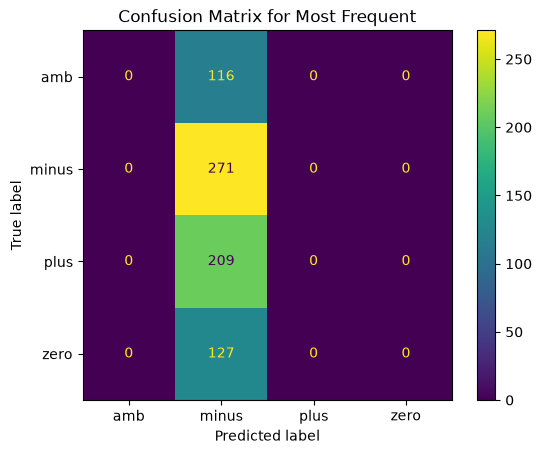

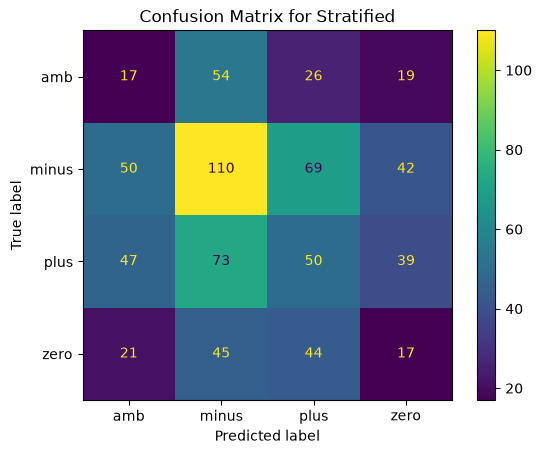

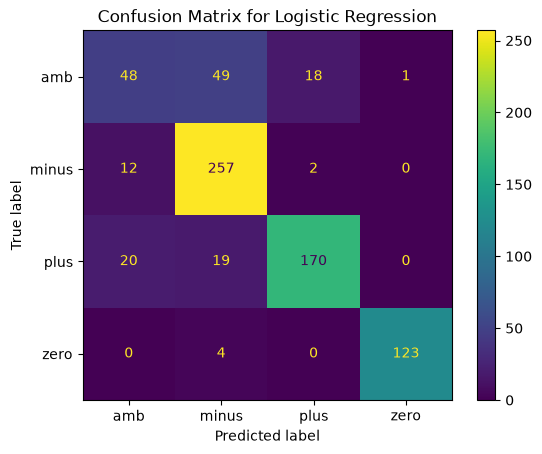

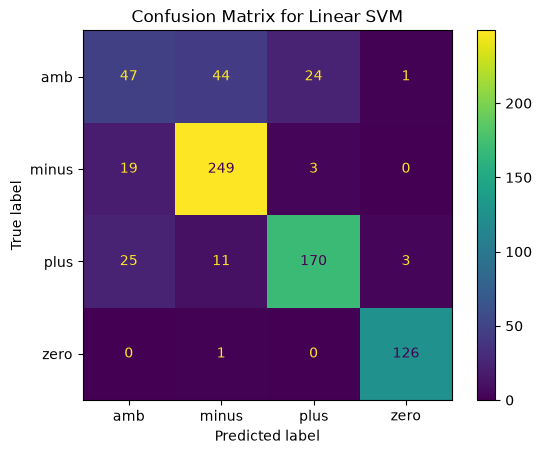

In [215]:
#TODO: ConfusionMatrix
for pipeline, model_name in zip((dummy_most_frequent, dummy_stratified, pipeline_lr, pipeline_svc),('Most Frequent', 'Stratified', 'Logistic Regression', 'Linear SVM')):
    y_pred = pipeline.predict(valid)
    confusion_matrix_svc = ConfusionMatrixDisplay.from_predictions(y_valid, y_pred)
    confusion_matrix_svc.ax_.set_title(f'Confusion Matrix for {model_name}')
    plt.show()


# Zadanie 6: Interpretacja wartości

Proszę znaleźć i wskazać trzy największe wartości poza przekątną. Każdą taką wartość należy skomentować jednym zdaniem interpretacji.

Przykład formy (treść jest przykładowa, proszę opisać własne wyniki):

> Model często klasyfikuje `X` jako `Y`, co może sugerować, że ______.

> Analiza dla modelu **Linear SVM** 
> 
> 1. Model często klasyfikuje `amb` jako `minus`, co może sugerować, że opine niejednoznaczne są przez niego najczęściej mylnie interpretowane jako negatywne.
> 
> 2. Model często klasyfikuje `plus` jako `amb`, co może sugerować, że opinie pozytywne zawierają mieszany kontekst, który model uznaje za niejednoznaczny.
> 
> 3. Model często klasyfikuje `amb` jako `plus`, co może sugerować, że część opini niejednoznacznych zawiera też elementy pozytywne.


# Word n-grams vs character n-grams

Polski jest językiem fleksyjnym. Jakie ma to znaczenie w przetwarzaniu języka?

Porównamy teraz dwie reprezentacje:

### A. słowa
```python
analyzer="word", ngram_range=(1, 2)
```

### B. znaki
```python
analyzer="char_wb", ngram_range=(3, 5)
```

Pozostałe parametry (`min_df=2`, `sublinear_tf=True`) muszą być takie same w obu wariantach, a `max_features` podany jawnie. Proszę raportować liczbę cech. Inaczej porównujemy nie reprezentację, tylko jej rozmiar (zasada „zmieniamy jeden element").

Character n-grams potrafią częściowo radzić sobie z:

- odmianą,
- literówkami,
- wariantami słowotwórczymi,
- nieformalną pisownią.

### Hipoteza

Która reprezentacja będzie lepsza na polskich recenzjach?

Proszę sformułować hipotezę przed wykonaniem eksperymentu.

In [152]:
#TODO: word_ngrams vs. char_ngrams

> Według mnie lepiej poradzi sobie wariant **B** czyli `char_wb` ponieważ, będzie on wstanie zamaskować błędy ortograficzne i skupić się znaczeniu słowa. Jednak ciekawym eksperymentem, byłoby połączenie obu wariantów.


# Zadanie 7: Ablacja (Ablation study)

Proszę porównać co najmniej 4 warianty:

1. word unigram,
2. word `(1, 2)`,
3. char `(3, 5)`,
4. word `(1, 2)` z inną wartością `min_df` albo `max_features`.

Proszę użyć tego samego LinearSVC.

> UWAGA: zmieniamy jeden element pipeline'u i sprawdzamy, co rzeczywiście daje poprawę.

In [216]:
#TODO: ablation_study

word_unigram = TfidfVectorizer(min_df=2, max_features=50_000, sublinear_tf=True)
word_12 = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True)
char_35 = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, max_features=50_000, sublinear_tf=True)
word_12_1 = TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=50_000, sublinear_tf=True)
word_char_union = FeatureUnion([
    ('word_tfidf', TfidfVectorizer(
        analyzer='word',
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True,
        max_features=25000,
        ),
    ),
    ('char_tfidf', TfidfVectorizer(
        analyzer='char_wb',
        ngram_range=(3, 5),
        min_df=2,
        sublinear_tf=True,
        max_features=25000,
        ),
    ),
])
model = LinearSVC(random_state=RANDOM_STATE)

vectorizers_to_test = [
    ('Word Unigram', word_unigram),
    ('Word Unigram+Bigram', word_12),
    ('Char n-grams (3-5)', char_35),
    ('Word Unigram+Bigram (min_df=1)', word_12_1),
    ('Word + Char Union', word_char_union),
]

for name, vec in vectorizers_to_test:
    print(f'')
    pipeline = Pipeline([
        ('vectorizer', vec),
        ('classifier', LinearSVC(random_state=42)),
    ])
    report = trigger_pipeline(pipeline, train, y_train, valid, y_valid)[1]
    print(f'========================================')
    print(f'Model Representation: {name}')
    print(f'========================================')
    print(classification_report(report['target'], report['pred']))
    print('\n')




Model Representation: Word Unigram
              precision    recall  f1-score   support

         amb       0.51      0.41      0.46       116
       minus       0.80      0.90      0.85       271
        plus       0.87      0.81      0.84       209
        zero       0.98      0.98      0.98       127

    accuracy                           0.81       723
   macro avg       0.79      0.78      0.78       723
weighted avg       0.81      0.81      0.81       723




Model Representation: Word Unigram+Bigram
              precision    recall  f1-score   support

         amb       0.52      0.41      0.45       116
       minus       0.82      0.92      0.86       271
        plus       0.86      0.81      0.84       209
        zero       0.97      0.99      0.98       127

    accuracy                           0.82       723
   macro avg       0.79      0.78      0.78       723
weighted avg       0.81      0.82      0.81       723




Model Representation: Char n-grams (3-5)
     

> TODO KOMENTARZ


# Analiza błędów

To jest jedna z najważniejszych części laboratorium.

Żeby zrozumieć, jak i do jakich danych możemy nasz model zastosować, pytamy:

> „Jakie typy błędów popełnia model?”

Proszę zbudować DataFrame z:

- tekstem,
- gold labels,
- predykcją,
- informacją `correct`,
- długością tekstu.


In [217]:
#TODO: error_analysis
error_analysis = rep_lr.copy()
error_analysis['correct'] = error_analysis['target'] == error_analysis['pred']
error_analysis['text_len'] = len(error_analysis['text'])
error_analysis.head()

,text,target,pred,y_prob,correct,text_len
5783,"pani doktor bardzo miła , ale szkła dobrane mam źle - w gabinecie było ciemno ( nieodpowiednie oświetlenie gabinetu ) , a soczewki których używa okulista w gabinecie do badania...",minus,minus,0.560301,True,723
5784,"pani doktor jest rzeczowa , odpowiada na każde pytanie konkretnie , nie ogólnikami , co bardzo istotne . spodobało mi się również podczas wizyty u pani , jej szczera opinia i p...",plus,plus,0.456500,True,723
5785,powinno być zero albo nawet - 10 . najgorszy lekarz u jakiego dotychczas była m . poszła m z 3 miesięcznym niemowlakiem ze względu na kolki . dostała m zestaw wszystkich możliw...,minus,minus,0.820233,True,723
5786,swoje osiągnięcie mańka zaprezentował podczas trwającego od czwartku do piątku w katowicach kongresu „ investing in medical innovations ” . opiera się ono na badaniach przeprow...,zero,zero,0.635867,True,723
5787,""" to wymaga współpracy z instytutami badawczymi , wielkim przemysłem i wyszukiwania innowacyjnych pomysłów , które powstają w czasie badań naukowych , a potem wprowadzania ich ...",zero,zero,0.902704,True,723



# Zadanie 8: Zacne przypadki porażek

Proszę wylosować (`random_state=RANDOM_STATE`) 10 błędnych przykładów i dodatkowo wybrać 5 błędów o najwyższej pewności modelu (maksimum z predict_proba dla LogisticRegression). Każdemu proszę ręcznie przypisać kategorię błędu. Losowanie, a nie ręczny wybór, zapewnia reprezentatywność taksonomii.

Proponowana taksonomia:

- `AMBIGUOUS_GOLD`: etykieta sama jest dyskusyjna,
- `MIXED_SENTIMENT`: tekst zawiera pozytywne i negatywne fragmenty,
- `NEGATION`: problem z negacją,
- `IRONY_SARCASM`,
- `LONG_CONTEXT`,
- `VERY_SHORT`,
- `DOMAIN_TERM`,
- `SPELLING_NOISE`,
- `NON_REVIEW`: tekst wygląda na artykuł prasowy, a nie recenzję,
- `PRETOKENIZATION`: błąd związany ze spacjowaniem interpunkcji lub odciętymi końcówkami (`miała m`, `Był em`),
- `OTHER`.

Jeśli są potrzebne, proszę dodać wasne klasy.

### Wynik

| error_type | count | przykład | obserwacja |
|---|---:|---|---|

In [ ]:
from enum import Enum, auto

class ErrorCategory(Enum):
    AMBIGUOUS_GOLD = auto()
    MIXED_SENTIMENT = auto()
    NEGATION = auto()
    IRONY_SARCASM = auto()
    LONG_CONTEXT = auto()
    VERY_SHORT = auto()
    DOMAIN_TERM = auto()
    SPELLING_NOISE = auto()
    NON_REVIEW = auto()
    PRETOKENIZATION = auto()
    OTHER = auto()

sample_errors = error_analysis.iloc[error_analysis['correct'] == False].sample(n=10, random_state=RANDOM_STATE)

pd.set_option("display.max_colwidth", 500)
display(sample_errors)
pd.set_option("display.max_colwidth", 180)


,text,target,pred,y_prob,correct,text_len
5910,"była m zadowolona z przebiegu leczenia , ale niestety rozczarowała m się na sam koniec kiedy dostała m wadliwe wkładki retencyjne ( górna wyskakiwała a dolna była zrobiona źle i nie dało się jej włożyć ) a pani nie chciała się ze mną spotkać żeby je poprawić tylko odesłała mnie do najbliższego gabinetu dentystycznego żeby mi je podpiłowali w efekcie czego dzisiaj chcą założyć mi po raz drugi aparat : (",amb,minus,0.703061,False,723
6085,"wizyta była miła , ale nie stać mnie na tą klinikę . szkoda bo pani doktor ma mikroskop , którego szukała m dwa lata by wyciągnąć ze starego zęba leczonego kanałowo urwany kawałek metalu . człowieka na rencie nie stać na nic i tu nie ma winy pani doktor . pozdrawiam serdecznie .",plus,minus,0.590055,False,723
6043,"do pani doktor ewy pawlak trafił em po przeczytaniu pozytywnych opinii na jej temat . niestety , bardzo się rozczarował em . konkrety . . . pani ewa wystawiła diagnozę jeszcze przed zapoznaniem się z dostarczonymi wynikami badań . zaznaczę , że moje schorzenie jest bardzo poważne , a obrazy rezonansów magnetycznych niezwykle istotne . pani doktor nie włączyła żadnej z przyniesionych płyt tk , choćby ostatniego badania . ogólnie całą dokumentację medyczną przejrzała bardzo pobieżnie . przynajmniej przy pierwszej wizycie pacjenta wypadało by poświęcić troszkę więcej czasu . najwidoczniej czas to pieniądz - niektórzy zauważalnie wyznają tę zasadę . wielokrotne spojrzenia na zegarek , wreszcie wprost wrócenie mi uwagi , że już 10min temu powinien wejść następny pacjent . cóż , wypadało by choć troszkę zamaskować swoje zarobkowe podejście do pacjentów . inną kwestią jest poziom wiedzy pani doktor . lekarze nieraz nie biorą pod uwagę , iż osoba do nich przychodząca - pacjent - niekoniecznie jest kompletnym laikiem . ludzie , którzy od lat walczą z poważną chorobą , konsultują się z wieloma specjalistami , zgłębiają wiele publikacji - często dobrze orientują się w medycznej terminologii . pani ewa najwyraźniej nie bierze takiego faktu pod uwagę . swoje , jakkolwiek budzące zastrzeżenia ( sprzeczne z wszystkimi innymi neurologami u których był em ! ) , opinie wydaje niezwykle szybko i swobodnie . dobra ocena pacjenta to dobrze przeprowadzony wywiad . niestety , pani doktor zdecydowanie woli mówić niż słuchać . zgodzę się z przedmówcą , nie idźcie do doktor ewy pawlak z przypadkiem poważnego schorzenia . być może , bardzo lekki i szybki sposób podejścia do pacjenta wystarczy do analizy prostych schorzeń . chciał by m , żeby taki był mój przypadek . osobom potrzebującym naprawdę specjalistycznej porady - zdecydowanie odradzam !",minus,plus,0.440578,False,723
6277,"bardzo przyjemny hotel , położony w lekko ponurej okolicy , ale po wejściu do środka nie ma to absolutnie znaczenia . wiele miejsc parkingowych , świetna i bogato wyposażona strefa wellness . bardzo dobry masaż . jedyny mały minus - niewielki basen , typowo rekreacyjny - dla nas był wystarczający , ale dla osób , które lubią trochę więcej popływać mógł by to być problem . bardzo blisko do rynku i do zamku . byli śmy zimą , ale od razu widać , że latem było by tam o wiele przyjemniej - np . altana przy restauracji jest bardzo duża i w zieleni musi wyglądać imponująco . ogólnie - hotel z pewnością wart polecenia !",plus,amb,0.453453,False,723
6145,"hotel nowy , duże pokoje , miejsca do siedzenia i stoliki w jednym pomieszczeniu , a sypialnia w drugim ( na 1 piętrze ) . brakowało mi miejsca na umywalce na jakieś drobiazgi , bardzo dobre kosmetyki nie wysuszające skóry . śniadania standardowe jeśli chodzi o bufet , jednak pyszne ciasta w trzech rodzajach i aromatyczna kawa . panie z obsługi smażą jajecznicę na bieżąco więc jest gorąca . lokalizacja bardzo dobra , blisko do niewielkiej galerii handlowej , do rynku i do katedry .",plus,amb,0.494634,False,723
6338,"witam , wybrali śmy się na wyjazd całą rodziną z dwójką dzieci ( 6 + 2 lata ) - dojazd z waszawy to koszmar , ale o to raczej nie

In [218]:
error_report = [
    {'error_type': ErrorCategory.AMBIGUOUS_GOLD, 'id': 5910},
    {'error_type': ErrorCategory.NEGATION,'id': 6085},
    {'error_type': ErrorCategory.LONG_CONTEXT,'id': 6043},
    {'error_type': ErrorCategory.MIXED_SENTIMENT,'id': 6277},
    {'error_type': ErrorCategory.MIXED_SENTIMENT,'id': 6145},
    {'error_type': ErrorCategory.AMBIGUOUS_GOLD,'id': 6338},
    {'error_type': ErrorCategory.MIXED_SENTIMENT,'id': 6175},
    {'error_type': ErrorCategory.AMBIGUOUS_GOLD,'id': 6497},
    {'error_type': ErrorCategory.MIXED_SENTIMENT,'id': 6343},
    {'error_type': ErrorCategory.MIXED_SENTIMENT ,'id': 5831},
]

error_summary = pd.DataFrame(error_report)
display(error_summary)

,error_type,id
0,ErrorCategory.AMBIGUOUS_GOLD,5910
1,ErrorCategory.NEGATION,6085
2,ErrorCategory.LONG_CONTEXT,6043
3,ErrorCategory.MIXED_SENTIMENT,6277
4,ErrorCategory.MIXED_SENTIMENT,6145
5,ErrorCategory.AMBIGUOUS_GOLD,6338
6,ErrorCategory.MIXED_SENTIMENT,6175
7,ErrorCategory.AMBIGUOUS_GOLD,6497
8,ErrorCategory.MIXED_SENTIMENT,6343
9,ErrorCategory.MIXED_SENTIMENT,5831


### Wynik

| error_type | count | przykład | obserwacja |
|---|---:|---|---|
| AMBIGUOUS_GOLD | 3 | "wizyta neutralna ... zobaczymy jak będzie przebiegało leczenie" | Etykieta docelowa jest bynajmniej dyskusyjna jeśli nie błęda, daje nam to do zrozumienia, że powinniśmy walidowć dane na których trenujemy i testujemy model|
| MIXED_SENTIMENT | 5 | "bardzo przyjemny hotel ... ale niewielki basen i kiepskie jedzenie" | Tekst łączy mocne opinie pozytywne i negatywne, co powoduje niejednoznaczność między klasami. |
| NEGATION | 1 | "nie polecam ... nie stać mnie na tę klinikę" | Negacja zmienia sens zdania, a model czasem pomija ją i przewiduje klasę odwrotną. |
| LONG_CONTEXT | 1 | "długi opis problemów medycznych, kolejnych wizyt i niezadowolenia z leczenia" | Długi kontekst zawiera wiele drobnych opinii, przez co model nie łapie głównego sentymentu. |


# Czy długość tekstu zmienia jakość?

PProszę podzielić split walidacyjny na 4 koszyki długości według **kwartyli** `n_words` z Lab 1 (`pd.qcut(val_df["n_words"], 4, duplicates="drop")`, liczone regexem `\w+`, nie `split()`). Stałe progi (0–10, 11–30, ...) mogą dać puste koszyki, bo recenzje w tym zbiorze są długie.

Proszę policzyć accuracy i macro-F1 osobno dla każdego koszyka.

### Uwaga

Macro-F1 na bardzo małym segmencie może być niestabilne. Istotne jest zaraportowanie `n`.

In [232]:
valid_df = pd.DataFrame({'text': valid, 'target': y_valid})
valid_df['n_words'] = valid_df['text'].str.findall(r'\w+').str.len()
valid_df.head()

,text,target,n_words
5783,"pani doktor bardzo miła , ale szkła dobrane mam źle - w gabinecie było ciemno ( nieodpowiednie oświetlenie gabinetu ) , a soczewki których używa okulista w gabinecie do badania...",minus,64
5784,"pani doktor jest rzeczowa , odpowiada na każde pytanie konkretnie , nie ogólnikami , co bardzo istotne . spodobało mi się również podczas wizyty u pani , jej szczera opinia i p...",plus,93
5785,powinno być zero albo nawet - 10 . najgorszy lekarz u jakiego dotychczas była m . poszła m z 3 miesięcznym niemowlakiem ze względu na kolki . dostała m zestaw wszystkich możliw...,minus,90
5786,swoje osiągnięcie mańka zaprezentował podczas trwającego od czwartku do piątku w katowicach kongresu „ investing in medical innovations ” . opiera się ono na badaniach przeprow...,zero,102
5787,""" to wymaga współpracy z instytutami badawczymi , wielkim przemysłem i wyszukiwania innowacyjnych pomysłów , które powstają w czasie badań naukowych , a potem wprowadzania ich ...",zero,110


In [233]:
# TODO: przypisanie koszyków i tabela: koszyk | n | accuracy | macro-F1
valid_df['basket'] = pd.qcut(valid_df['n_words'], 4, duplicates='drop')
baskets = valid_df['basket'].unique()
print(f'Baskets: {baskets}')
valid_df.head()

Baskets: [(27.999, 71.0], (71.0, 101.0], (101.0, 133.0], (133.0, 637.0]]
Categories (4, interval[float64, right]): [(27.999, 71.0] < (71.0, 101.0] < (101.0, 133.0] < (133.0, 637.0]]


,text,target,n_words,basket
5783,"pani doktor bardzo miła , ale szkła dobrane mam źle - w gabinecie było ciemno ( nieodpowiednie oświetlenie gabinetu ) , a soczewki których używa okulista w gabinecie do badania...",minus,64,"(27.999, 71.0]"
5784,"pani doktor jest rzeczowa , odpowiada na każde pytanie konkretnie , nie ogólnikami , co bardzo istotne . spodobało mi się również podczas wizyty u pani , jej szczera opinia i p...",plus,93,"(71.0, 101.0]"
5785,powinno być zero albo nawet - 10 . najgorszy lekarz u jakiego dotychczas była m . poszła m z 3 miesięcznym niemowlakiem ze względu na kolki . dostała m zestaw wszystkich możliw...,minus,90,"(71.0, 101.0]"
5786,swoje osiągnięcie mańka zaprezentował podczas trwającego od czwartku do piątku w katowicach kongresu „ investing in medical innovations ” . opiera się ono na badaniach przeprow...,zero,102,"(101.0, 133.0]"
5787,""" to wymaga współpracy z instytutami badawczymi , wielkim przemysłem i wyszukiwania innowacyjnych pomysłów , które powstają w czasie badań naukowych , a potem wprowadzania ich ...",zero,110,"(101.0, 133.0]"


In [239]:
# TODO: wykres accuracy i macro-F1 vs koszyk (z podaniem n przy każdym słupku)

basket_analisis = []

for basket in baskets:
    df = valid_df.iloc[valid_df['basket'] == basket]
    y_pred = pipeline_lr.predict(df['text'])
    basket_analisis.append({
        'basket': basket,
        'accuracy': accuracy_score(df['target'], y_pred),
        'macro-f1': macro_f1_score(df['target'], y_pred),
        'n': df.shape[0]
    })

basket_analisis = pd.DataFrame(basket_analisis)
display(basket_analisis)

,basket,accuracy,macro-f1,n
0,"(27.999, 71.0]",0.786885,0.743764,183
1,"(71.0, 101.0]",0.805556,0.764279,180
2,"(101.0, 133.0]",0.900552,0.853225,181
3,"(133.0, 637.0]",0.815642,0.769337,179



# Czego właściwie nauczył się model?

Dla modelu liniowego możemy obejrzeć cechy o największych wagach.

To nie jest pełne wyjaśnienie modelu, ale bardzo użyteczne narzędzie diagnostyczne.

Dla każdej klasy proszę wypisać:

- 15 cech o najwyższej dodatniej wadze,
- 15 o najniższej.

Tym samym proszę sprawdzić, czy model uczy się sensownych sygnałów, czy przypadkowych artefaktów.


In [ ]:
# TODO: dla LogisticRegression: pipeline.named_steps["tfidf"].get_feature_names_out() oraz clf.coef_ (kształt: klasy × cechy). Po 15 cech o najwyższej i najniższej wadze na klasę


# Zadanie 9: Ewaluacja cech

Proszę znaleźć:

1. trzy cechy, które wyglądają sensownie,
2. trzy cechy, które mogą być skrótem / artefaktem (podpowiedź: proszę przejrzeć tokeny krótkie i funkcyjne oraz pozostałości po pre-tokenizacji tekstów, np. `em`, `śmy`; domyślny tokenizer odrzuca tokeny jednoznakowe, więc `m` w `miała m` zniknie, a `em` w `Był em` zostanie),
3. jedną cechę, której obecność Cię zaskoczyła.

Następnie proszę odpowiedzieć:

> Czy wysoka waga cechy oznacza związek przyczynowy?


# Prawdopodobieństwo predykcji i selektywna klasyfikacja

`LogisticRegression` zwraca `predict_proba`.

Możemy zbudować prostą zasadę:

> jeśli maksymalne prawdopodobieństwo < próg, model nie odpowiada.

To nazywamy m.in. abstention, reject option albo selektywną klasyfikacją.

W prawdziwym wdrożonym systemie czasem lepiej powiedzieć:

> „nie wiem / skieruj do człowieka”

niż wymusić odpowiedź.


In [ ]:
#TODO: predict_proba


# Zadanie 10: Pokrycie i jakość

Dla progów:

`0.40, 0.50, 0.60, 0.70, 0.80, 0.90`

proszę policzyć:

- `coverage`: na jakiej części danych model udziela odpowiedzi,
- accuracy na zaakceptowanych przykładach,
- macro-F1 na zaakceptowanych przykładach.

Uwaga: przy wysokich progach niektóre klasy mogą nie wystąpić wśród zaakceptowanych przykładów. Proszę liczyć `f1_score(..., labels=CLASSES, average="macro", zero_division=0)` i raportować `n` zaakceptowanych. Prawdopodobieństwa dostępne są tylko dla LogisticRegression (LinearSVC nie ma `predict_proba`).

Proszę narysować:

`coverage` vs `accuracy`

### Pytanie

Czy da się zwiększyć jakość systemu bez zmiany modelu? Jeśli tak, to jak?

In [ ]:
# TODO: coverage vs accuracy

In [ ]:
# TODO: improvement_experiment


# Tuning hiperparametrów

Sprawdzimy jeden parametr Logistic Regression:

`C ∈ {0.1, 0.5, 1, 2, 5}`

Obliczeń dokonujemy na splicie walidacyjnym. To wystarczy, by przećwiczyć prawidłowy protokół:

`train → validation → wybór → test`


## Zadanie 11: Strojenie hiperparametru C

Proszę przeprowadzić strojenie hiperparametru C dla modelu regresji logistycznej.
- przetestować wartości C: 0.1, 0.5, 1.0, 2.0 i 5.0.
- dla każdej wartości wytrenować osobny model LogisticRegression na reprezentacji TF-IDF zbioru treningowego.
- wykonać predykcję dla zbioru walidacyjnego.
- obliczyć metryki jakości modelu, w szczególności macro F1.
- zapisać wyniki dla wszystkich wartości C w tabeli.
- posortować wyniki malejąco według macro F1.
- wybrać wartość C, dla której model uzyskał najlepszy wynik na zbiorze walidacyjnym.
Jeśli najlepsze C leży na brzegu siatki (5.0), proszę poszerzyć siatkę i powtórzyć.

Na końcu krótko odpowiedzieć: jak zmiana wartości C wpłynęła na jakość klasyfikacji i która wartość została wybrana?

In [ ]:
# TODO: strojenie C na validation (nie na test!)


# Zadanie 12: Finalista

Na podstawie splitu proszę wybrać jeden finalny pipeline.

Nie musi to być model z absolutnie najwyższym wynikiem, jeśli różnica jest minimalna, a koszt znacząco większy.

Proszę uzasadnić:

> **Wybrany model:** ...

> **Dlaczego:** ...

> **Najważniejszy trade-off:** ...



# Zadanie 13: Ostateczny test modelu

Kiedy mamy już wszystkie niezbędne informacje, wolno nam użyć test setu do finalnej oceny.

Proszę wybrać konfigurację na podstawie validation i:

1. połącz `train + validation`,
2. wytrenuj model od nowa,
3. oceń dokładnie raz na `test`.

Proszę nie poprawiać konfiguracji po zobaczeniu testu ;)


In [ ]:
#TODO: TEST


# NLP Arena #1

Teraz model musi zostać oceniony jak system, a nie tylko liczba F1.

Dla finalistów raportujemy:

### Quality
- macro-F1,
- accuracy.

### Speed
- czas treningu,
- inference ms / dokument.

### Size
- rozmiar zapisanego pipeline'u.

### Robustness
- wynik na krótkich tekstach,
- wynik na długich tekstach.

### Interpretability
- czy możemy obejrzeć ważne cechy?

## Kategorie

**Best Quality**: najwyższe macro-F1  
**Speed Demon**: najniższe inference time  
**Tiny but Mighty**: najlepszy stosunek jakości do rozmiaru  
**Occam Award**: najprostszy system blisko najlepszego wyniku  
**Failure Analyst**: najlepsza analiza błędów


Proszę zapisać wytrenowany model do pliku i zmierzyć podstawowe parametry związane z jego wykorzystaniem.
- zapisać końcowy model do pliku w formacie joblib.
- obliczyć rozmiar zapisanego modelu w MB.
- wyświetlić czas treningu modelu w sekundach.
- obliczyć średni czas inferencji dla jednego dokumentu i podać go w milisekundach na dokument (ms/doc).
- zapisać otrzymane wartości i wykorzystać je później do porównania z innymi modelami.

Porównując modele, proszę zwrócić uwagę nie tylko na jakość klasyfikacji, ale również na ich rozmiar oraz koszt treningu i inferencji.

# Zadanie 14: Baseline Boss Fight

Zadanie związane z areną, skupiamy się w nim na następujących aspektach:

### A. Word + char features
Proszę połączyć reprezentację słowną i znakową przez `FeatureUnion`.

### B. Class weights
Sprawdzić `class_weight="balanced"`. Czy macro-F1 rośnie? Które klasy zyskują, a które tracą?

### C. Learning curve
Proszzę wytrenować ten sam model na:

- 10% train,
- 25%,
- 50%,
- 75%,
- 100%.

Proszę powtórzyć dla 3 różnych seedów losowania podzbiorów i raportować średnią ± odchylenie.

Proszę narysować:

`liczba przykładów → macro-F1`

Proszę odpowiedzieć: Czy bardziej opłaca się zmienić model, czy zdobyć więcej danych?

### D. Robustness test
Proszę zastosować zaburzenia do całego zbioru validation (n=723; 100 przykładów daje zbyt szeroki przedział ufności). Proszę wprowadzić kontrolowany szum:

- usunąć polskie znaki,
- dodać literówki,
- zmienić wielkość liter.

Proszę sprawdzić spadek wyniku word-TF-IDF i char-TF-IDF.

### E. Cost-aware model selection
Proszę zdefiniować własny score:

```text
utility = macro_f1 - λ * log10(model_size_mb + 1)
```
Proszę sprawdzić λ ∈ {0.01, 0.05, 0.1} i sprawdzić, czy najlepszy model nadal wygrywa.


# Zadanie 15: Karta modelu

Proszę utworzyć:

```text
artifacts/baseline_model_card.md
```

Minimalna zawartość:
- Jaki pipeline?
- Co przewiduje?
- Na czym został wytrenowany?
- Jakie splity i jaka główna metryka?
- Validation i final test.
- Czas treningu i inference.
- Co wynika z zaobserwowanych porażek?
- Czy próg confidence ma sens?
- Do czego model może być użyty? Do czego nie powinien być używany?



# Raport końcowy

Proszę podsumować pracę i określić:

1. **Najlepszy model:** ...
2. **Poprawa względem majority baseline:** ...
3. **Najtrudniejsza klasa:** ...
4. **Najważniejszy typ błędu:** ...
5. **Najważniejszy trade-off jakość/koszt:** ...
6. **Czy na tym etapie potrzebujemy większego modelu?** ...

Każde sformułowanie proszę uzasadnić.


# Warunki ukończenia laboratorium

Laboratorium jest skończone, jeśli zawiera:

- [x] majority baseline (oba warianty `DummyClassifier`);
- [x] TF-IDF i opis macierzy rzadkiej;
- [x] Logistic Regression;
- [x] Linear SVM;
- [x] leaderboard na validation z przedziałami ufności;
- [x] classification report;
- [x] confusion matrix;
- [x] ablację word vs char n-grams;
- [x] Failure Gallery z ręczną taksonomią błędów;
- [ ] analizę jakości względem długości tekstu;
- [ ] porównanie wag modelu liniowego;
- [ ] coverage vs quality;
- [ ] strojenie C (tabela, wybór na validation);
- [ ] wybór finalisty bez używania test setu;
- [ ] ostateczny test: train + validation, dokładnie jeden raz na test;
- [ ] zapisany model `.joblib` i pomiary (rozmiar, czas treningu, ms/doc);
- [ ] NLP Arena #1;
- [ ] Baseline Boss Fight;
- [ ] `baseline_model_card.md`;
- [ ] wnioski końcowe.